### Fresnel Reflection and Transmission Coefficients

#### Amplitude Coefficients

**Reflection amplitude (TE polarization):**
$$
r_s = -\frac{\sin(\alpha - \beta)}{\sin(\alpha + \beta)}
$$

**Reflection amplitude (TM polarization):**
$$
r_p = \frac{\tan(\alpha - \beta)}{\tan(\alpha + \beta)}
$$

**Transmission amplitude (TE polarization):**
$$
t_s = \frac{2 \sin(\beta) \cos(\alpha)}{\sin(\alpha + \beta)}
$$

**Transmission amplitude (TM polarization):**
$$
t_p = \frac{t_s}{\cos(\alpha - \beta)}
$$

---

#### Power (Intensity) Coefficients

**Reflection coefficient (TE polarization):**
$$
R_s = |r_s|^2
$$

**Reflection coefficient (TM polarization):**
$$
R_p = |r_p|^2
$$

**Transmission coefficient (TE polarization):**
$$
T_s = |t_s|^2 \cdot \frac{n_2}{n_1} \cdot \frac{\cos(\beta)}{\cos(\alpha)}
$$

**Transmission coefficient (TM polarization):**
$$
T_p = |t_p|^2 \cdot \frac{n_2}{n_1} \cdot \frac{\cos(\beta)}{\cos(\alpha)}
$$

---

- Here $\alpha$ is the incidence angle, $\beta$ is the refraction angle obtained from Snell’s law:
$$
n_1 \sin(\alpha) = n_2 \sin(\beta).
$$

- The factor $\tfrac{n_2}{n_1}$ converts energy flux densities between media ($|\langle S \rangle| \propto n E^2$).  
- The factor $\tfrac{\cos(\beta)}{\cos(\alpha)}$ accounts for the projection change due to refraction (see Eq. (9.202) in the book).  
- Under **total internal reflection (TIR)** when $\sin\beta > 1$, $\beta$ becomes complex and physically:
$$
R_s = R_p = 1, \quad T_s = T_p = 0.
$$


In [15]:
import numpy as np
import matplotlib.pyplot as plt
n_pts = 256                                  # number of sample points
alpha = (np.pi/2) * np.arange(1, n_pts+1) / n_pts   # (0, π/2], avoid exactly 0
alpha_deg = alpha * 180 / np.pi

# ====== Case A: air (n1=1.0) -> glass (n2=1.5) ======
n1, n2 = 1.0, 1.5

# Snell's law: n1*sin(alpha) = n2*sin(beta)
sin_beta = np.sin(alpha) * n1 / n2
beta = np.arcsin(sin_beta)

# Amplitudes (your formulas)
rs = -np.sin(alpha - beta) / np.sin(alpha + beta)          # TE reflection amp
rp =  np.tan(alpha - beta) / np.tan(alpha + beta)          # TM reflection amp
ts =  2*np.sin(beta)*np.cos(alpha) / np.sin(alpha + beta)  # TE transmission amp
tp =  ts / np.cos(alpha - beta)                             # TM transmission amp

# Powers
Rs = np.abs(rs)**2
Rp = np.abs(rp)**2
Ts = (np.abs(ts)**2) * (n2/n1) * (np.cos(beta)/np.cos(alpha))
Tp = (np.abs(tp)**2) * (n2/n1) * (np.cos(beta)/np.cos(alpha))


# ====== Case B: glass (n1=1.5) -> air (n2=1.0) with TIR handling ======
n1_B, n2_B = 1.5, 1.0

sin_beta_B = np.sin(alpha) * n1_B / n2_B
sin_beta_B_clipped = np.clip(sin_beta_B, -1.0, 1.0)
beta_B = np.arcsin(sin_beta_B_clipped)

rs_B = -np.sin(alpha - beta_B) / np.sin(alpha + beta_B)
rp_B =  np.tan(alpha - beta_B) / np.tan(alpha + beta_B)
ts_B =  2*np.sin(beta_B)*np.cos(alpha) / np.sin(alpha + beta_B)
tp_B =  ts_B / np.cos(alpha - beta_B)

Rs_B = np.abs(rs_B)**2
Rp_B = np.abs(rp_B)**2
Ts_B = (np.abs(ts_B)**2) * (n2_B/n1_B) * (np.cos(beta_B)/np.cos(alpha))
Tp_B = (np.abs(tp_B)**2) * (n2_B/n1_B) * (np.cos(beta_B)/np.cos(alpha))



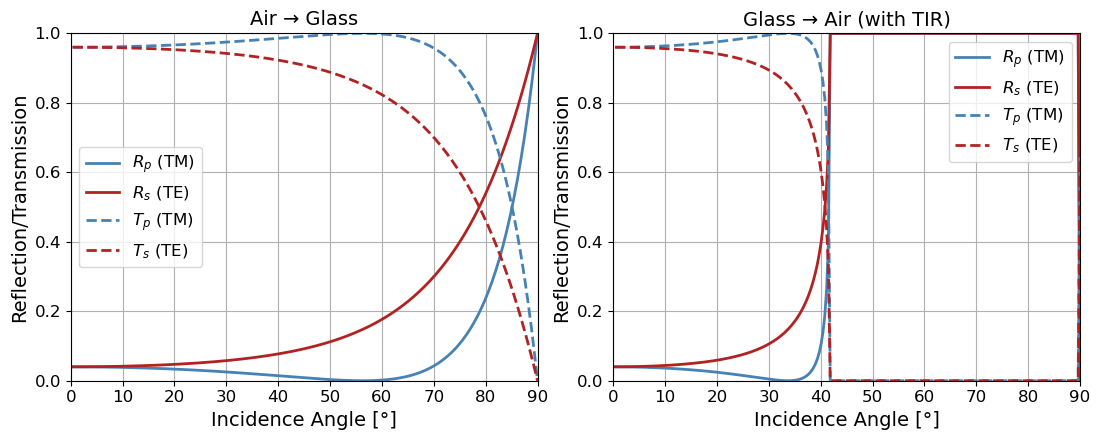

In [ ]:
plt.figure(figsize=(11, 4.5))

# Left: Air -> Glass
ax1 = plt.subplot(1, 2, 1)
ax1.plot(alpha_deg, Rp, label=r'$R_p\ (\mathrm{TM})$', color='steelblue', linestyle='-', linewidth=2)
ax1.plot(alpha_deg, Rs, label=r'$R_s\ (\mathrm{TE})$', color='firebrick', linestyle='-', linewidth=2)
ax1.plot(alpha_deg, Tp, label=r'$T_p\ (\mathrm{TM})$', color='steelblue', linestyle='--', linewidth=2)
ax1.plot(alpha_deg, Ts, label=r'$T_s\ (\mathrm{TE})$', color='firebrick', linestyle='--', linewidth=2)
ax1.set_xlim(0, 90)
ax1.set_ylim(0, 1)
ax1.set_title("Air → Glass", fontsize=14)
ax1.set_xlabel("Incidence Angle [°]", fontsize=14)
ax1.set_ylabel("Reflection/Transmission", fontsize=14)
ax1.legend(fontsize=12, loc="best")
ax1.grid(True)
ax1.tick_params(axis='both', labelsize=12)

# Right: Glass -> Air (shows TIR)
ax2 = plt.subplot(1, 2, 2)
ax2.plot(alpha_deg, Rp_B, label=r'$R_p\ (\mathrm{TM})$', color='steelblue', linestyle='-', linewidth=2)
ax2.plot(alpha_deg, Rs_B, label=r'$R_s\ (\mathrm{TE})$', color='firebrick', linestyle='-', linewidth=2)
ax2.plot(alpha_deg, Tp_B, label=r'$T_p\ (\mathrm{TM})$', color='steelblue', linestyle='--', linewidth=2)
ax2.plot(alpha_deg, Ts_B, label=r'$T_s\ (\mathrm{TE})$', color='firebrick', linestyle='--', linewidth=2)
ax2.set_xlim(0, 90)
ax2.set_ylim(0, 1)
ax2.set_title("Glass → Air (with TIR)", fontsize=14)
ax2.set_xlabel("Incidence Angle [°]", fontsize=14)
ax2.set_ylabel("Reflection/Transmission", fontsize=14)
ax2.legend(fontsize=12, loc="best")
ax2.grid(True)
ax2.tick_params(axis='both', labelsize=12)

plt.tight_layout()
plt.show()